<div class="alert alert-success">

## Instructions to students

If the assignment was fetched from the assignments tab, do not change the name of the assignment file(s).

### Code answers

In questions that require you to write code, there will be a code cell containing: 
    
<code># YOUR CODE HERE</code>
<br>
<code>raise NotImplementedError()</code>
    
When you are ready to write your answer, delete <code>raise NotImplementedError()</code> and write your code.

### Submitting your work
    
You should save your work before you submit ("Save" icon in top menu).
    
Before you submit, ensure that the notebook can be run from start to finish by pressing the "Restart & Run All" option in the "Kernel" menu above.
    
Once you are ready, go to the assignments tab on the Noteable landing page and click "Submit" on the relevant assignment.

</div>

### Question 1: Fitting Projectile Motion Data

In a laboratory experiment, the trajectory of a small projectile was measured. The horizontal position (`x`) and vertical position (`y`) were recorded at several points. 

You should assume an uncertainty of +/- 0.1m for all `y` values due to limitations of the instrumentation.

According to theory, the trajectory should follow a quadratic relationship of the form:

$$y(x) = ax^2 + bx + c$$

Your task is to fit this model to the experimental data, determine the best-fit values for the parameters `a`, `b`, and `c`, and find their uncertainties.

Create a function `fitter(x_data, y_data, y_errors, init)` that fits the particle's trajectory. This function should call a separately defined function named `quadratic_model(...)`, which describes the model used to fit the data. The ellipsis (`...`) in the `quadratic_model` definition indicates that you are responsible for defining the necessary parameters for this function.

The `fitter()` function should return the optimal fit parameters and the covariance matrix obtained from the SciPy `curve_fit()` function, taking into account the errors in the `y` measurements. 

Note: 

* Both functions, `quadratic_model` and `fitter`, are used in hidden tests and so must be defined as described above
* You must store the `x`, `y` and `y`-uncertainties in arrays called `x_data`, `y_data`, `y_errors` respectively as the hidden tests use these.

### Tasks:

1. Print the best fit parameters with their uncertainties


2. **Create two plots:**

   
   **(a)** Plot the data with errors and overlay the best fit curve as a red line

   **(b)** Draw the residual ratios on a second plot. The residual ratio is defined as the difference between the data and the fitted model for each data point
   
   The residuals plot visually represents how well your fit function models the data, and the values on the y-axis can be both positive and negative. If the fit function models the physical system well, the residuals should be randomly distributed above and below zero, indicating that only random experimental fluctuations are present.

IMPORTANT: To secure full marks, all plots need meaningful axis labels with units and your plot from part a) must have a meaningful legend

### Hints:

This fit is rather stable and initial values of `init=[1.0, 1.0, 1.0]` will be fine



### Experimental Data:

| Horizontal Position, x (m) | Vertical Position, y (m) | 
 | ----- | ----- | 
| 0.5 | 2.8 | 
| 1.0 | 4.6 | 
| 1.5 | 5.9 | 
| 2.0 | 7.2 | 
| 2.5 | 8.1 | 
| 3.0 | 8.5 | 
| 3.5 | 8.6 | 
| 4.0 | 8.2 | 
| 4.5 | 7.5 | 
| 5.0 | 6.4 | 
| 5.5 | 4.9 | 
| 6.0 | 3.1 | 

### Import Libraries

First, we import the necessary libraries: `numpy`, `matplotlib.pyplot` and `curve_fit` from `scipy.optimize`. DO NOT change the following cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

Optimal Parameters: [-0.74605395  4.92907093  0.4       ] 
 Optimal Covariances: [[ 0.00010661 -0.00069299  0.00080848]
 [-0.00069299  0.00475318 -0.00606364]
 [ 0.00080848 -0.00606364  0.0094997 ]] 
 Errors per Parameter: [0.01032538 0.06894331 0.09746638]


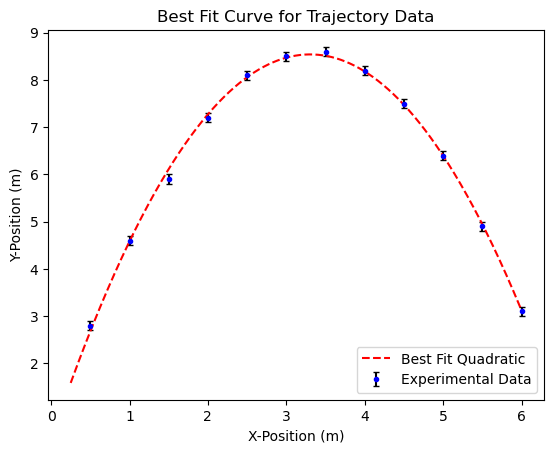

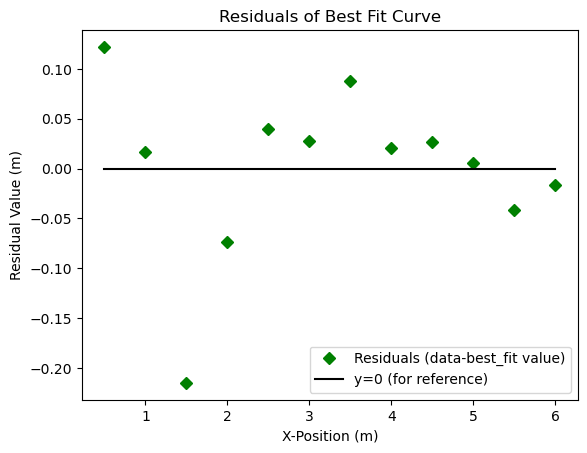

In [82]:
# YOUR CODE HERE
#create the sample data and errors
x_data = np.arange(0.5,6.5,0.5)

y_data=np.array([2.8, 4.6, 5.9, 7.2, 8.1, 8.5, 8.6, 8.2, 7.5, 6.4, 4.9, 3.1])

error=0.1
y_errors=np.ones(len(y_data))*error

init=[1.0, 1.0, 1.0] #initial guesses

#define quadratic model function
def quadratic_model(x,a,b,c): #CHECK
    return a*(x**2)+b*x+c

#define fitter function
def fitter(x_data, y_data,y_errors,init):
    params, covariances = curve_fit(quadratic_model, x_data, y_data, p0=init, sigma=y_errors)
    return params, covariances

#call function to fit and save as a function for plotting
opt_params, opt_cov=fitter(x_data,y_data,y_errors, init)
err_by_param=np.sqrt(np.diag(opt_cov))
print(f"Optimal Parameters:", opt_params,f"\n Optimal Covariances:", opt_cov, f"\n Errors per Parameter:", err_by_param)
best_model=np.poly1d(opt_params)


#PlOT 1
xdraw=np.linspace(0.25,6,1000)
fig1, ax=plt.subplots()
ax.errorbar(x_data, y_data,y_errors,fmt='.',color='b',ecolor='k',capsize=2, label="Experimental Data")
ax.plot(xdraw, best_model(xdraw),'--r', label="Best Fit Quadratic")
ax.set_xlabel("X-Position (m)")
ax.set_ylabel("Y-Position (m)")
ax.set_title("Best Fit Curve for Trajectory Data")
ax.legend()
plt.show()

#PLOT 2
#calculate the residuals
residuals=[]
for i in range(0,len(x_data)):
    difference = y_data[i]-best_model(x_data[i])
    residuals.append(difference)
residuals=np.array(residuals)

#make plot
fig2,ax2=plt.subplots()
ax2.plot(x_data, residuals, 'Dg', label = "Residuals (data-best_fit value)")
ax2.plot(x_data, np.zeros(12),'k', label = 'y=0 (for reference)')
ax2.set_xlabel("X-Position (m)")
ax2.set_ylabel("Residual Value (m)")
ax2.set_title("Residuals of Best Fit Curve")
ax2.legend()
plt.show()

In [ ]:
# Test cell, do not delete

In [ ]:
# Test cell, do not delete

Marks cell - do not delete

Tests - 3 marks; Plots - 4 marks (one mark for plot and one for labels/legends x2)